In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")

print(df.head())

   Transaction ID        Date Customer ID  Gender  Age Product Category  \
0               1  2023-11-24     CUST001    Male   34           Beauty   
1               2  2023-02-27     CUST002  Female   26         Clothing   
2               3  2023-01-13     CUST003    Male   50      Electronics   
3               4  2023-05-21     CUST004    Male   37         Clothing   
4               5  2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  
0         3              50           150  
1         2             500          1000  
2         1              30            30  
3         1             500           500  
4         2              50           100  


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

Data Types:
Transaction ID      int64
Date                  str
Customer ID           str
Gender                str
Age                 int64
Product Category      str
Quantity            int64
Price per Unit      int64
Total Amount        int64
dtype: object

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Duplicate Rows:
0


In [3]:
df["Date"] = pd.to_datetime(df["Date"])

df["Month"] = df["Date"].dt.month
df["Month Name"] = df["Date"].dt.strftime("%B")
df["Quarter"] = df["Date"].dt.quarter

print(df.head())
print("\nDate Data Type:", df["Date"].dtype)

   Transaction ID       Date Customer ID  Gender  Age Product Category  \
0               1 2023-11-24     CUST001    Male   34           Beauty   
1               2 2023-02-27     CUST002  Female   26         Clothing   
2               3 2023-01-13     CUST003    Male   50      Electronics   
3               4 2023-05-21     CUST004    Male   37         Clothing   
4               5 2023-05-06     CUST005    Male   30           Beauty   

   Quantity  Price per Unit  Total Amount  Month Month Name  Quarter  
0         3              50           150     11   November        4  
1         2             500          1000      2   February        1  
2         1              30            30      1    January        1  
3         1             500           500      5        May        2  
4         2              50           100      5        May        2  

Date Data Type: datetime64[us]


In [4]:
print("Mean:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].mean())

print("\nMedian:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].median())

print("\nMode:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].mode().iloc[0])

print("\nStandard Deviation:")
print(df[["Age", "Quantity", "Price per Unit", "Total Amount"]].std())

Mean:
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

Median:
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode:
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

Standard Deviation:
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


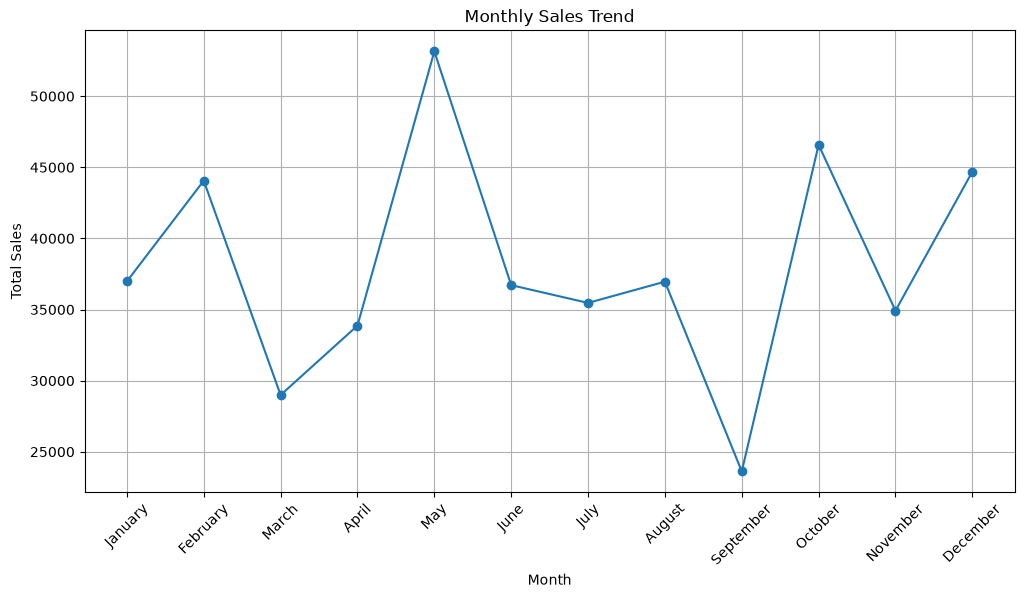

In [5]:
monthly_sales = df.groupby("Month Name")["Total Amount"].sum()

month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

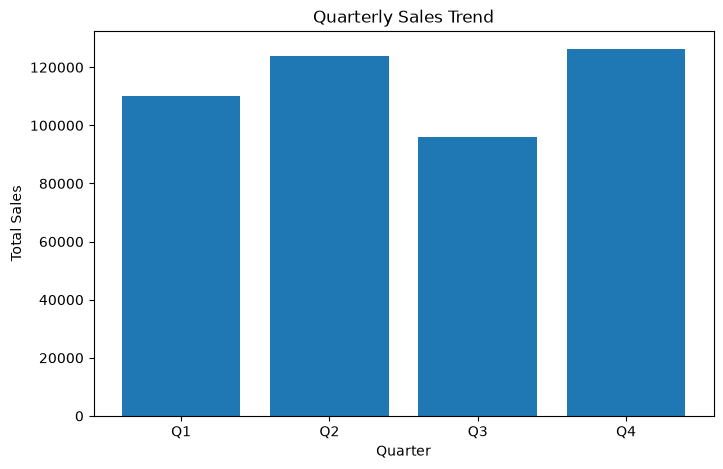

In [6]:
quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

plt.figure(figsize=(8, 5))
plt.bar(
    ["Q1", "Q2", "Q3", "Q4"],
    quarterly_sales.values
)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")

plt.show()

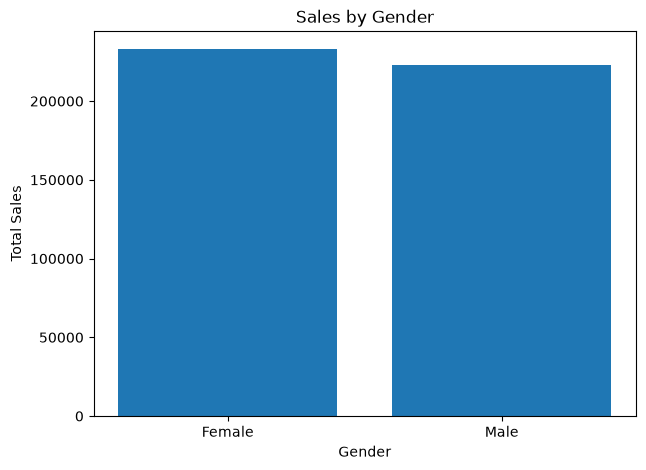

In [7]:
gender_sales = df.groupby("Gender")["Total Amount"].sum()

plt.figure(figsize=(7, 5))
plt.bar(gender_sales.index, gender_sales.values)

plt.title("Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")

plt.show()

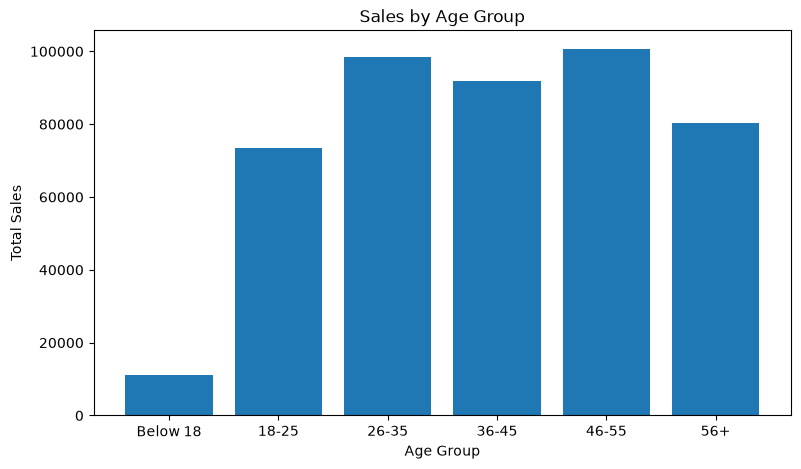

In [8]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 25, 35, 45, 55, 100],
    labels=["Below 18", "18-25", "26-35", "36-45", "46-55", "56+"]
)

age_group_sales = df.groupby(
    "Age Group", observed=False
)["Total Amount"].sum()

plt.figure(figsize=(9, 5))
plt.bar(age_group_sales.index.astype(str), age_group_sales.values)

plt.title("Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")

plt.show()

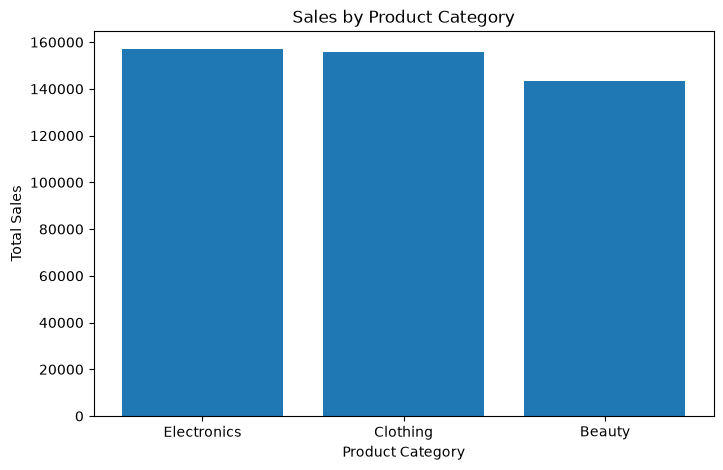

Sales by Product Category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [9]:
category_sales = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.show()

print("Sales by Product Category:")
print(category_sales)

In [10]:
top_10_sales = df.nlargest(10, "Total Amount")[
    ["Transaction ID", "Product Category", "Quantity", "Price per Unit", "Total Amount"]
]

print("Top 10 Highest-Value Transactions:")
print(top_10_sales)

Top 10 Highest-Value Transactions:
     Transaction ID Product Category  Quantity  Price per Unit  Total Amount
14               15      Electronics         4             500          2000
64               65      Electronics         4             500          2000
71               72      Electronics         4             500          2000
73               74           Beauty         4             500          2000
88               89      Electronics         4             500          2000
92               93           Beauty         4             500          2000
108             109      Electronics         4             500          2000
117             118      Electronics         4             500          2000
123             124         Clothing         4             500          2000
138             139           Beauty         4             500          2000


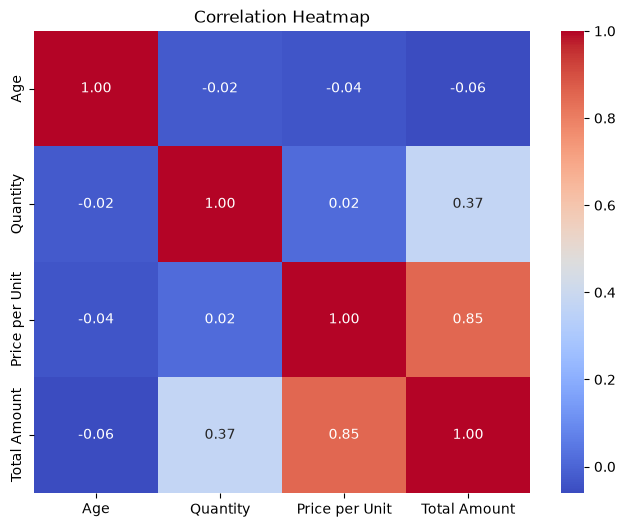

In [11]:
correlation = df[
    ["Age", "Quantity", "Price per Unit", "Total Amount"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

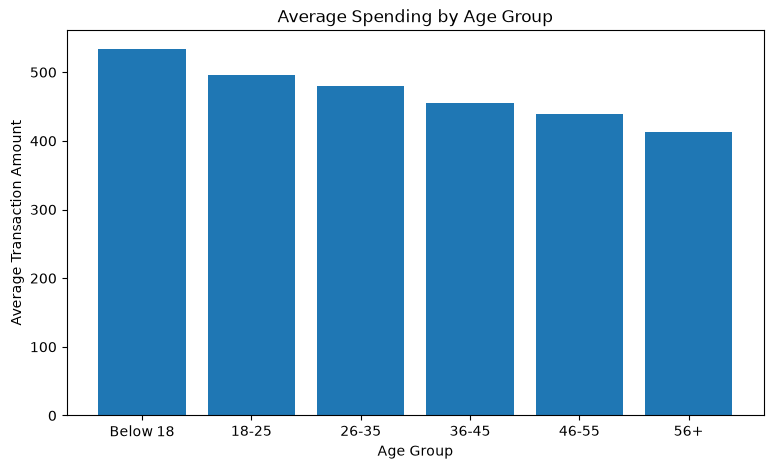

Average Spending by Age Group:
Age Group
Below 18    534.05
18-25       495.51
26-35       480.39
36-45       454.80
46-55       439.69
56+         412.36
Name: Total Amount, dtype: float64


In [12]:
average_spending_age = df.groupby(
    "Age Group", observed=False
)["Total Amount"].mean()

plt.figure(figsize=(9, 5))
plt.bar(
    average_spending_age.index.astype(str),
    average_spending_age.values
)

plt.title("Average Spending by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Amount")

plt.show()

print("Average Spending by Age Group:")
print(average_spending_age.round(2))

## Key Observations

### 1. Monthly Sales Trend
- Sales fluctuate throughout the year.
- May recorded the highest monthly sales.
- September recorded the lowest monthly sales.
- Sales increased sharply again in October.

### 2. Quarterly Sales Trend
- Q4 recorded the highest quarterly sales.
- Q3 recorded the lowest quarterly sales.
- Q2 also showed strong sales performance.

### 3. Sales by Gender
- Female customers generated slightly higher total sales than male customers.
- The difference between male and female sales is relatively small.

### 4. Sales by Age Group
- The 46-55 age group generated the highest total sales.
- The 26-35 age group also contributed strongly to total sales.
- Customers below 18 generated the lowest total sales.

### 5. Sales by Product Category
- Electronics generated the highest total sales.
- Clothing generated nearly similar sales to Electronics.
- Beauty recorded the lowest sales among the three categories.

### 6. Top 10 Highest-Value Transactions
- The highest transaction value was ₹2,000.
- Most of the highest-value transactions involved a quantity of 4 units at a price of ₹500 per unit.
- Electronics appeared most frequently among these high-value transactions.

### 7. Correlation Analysis
- Price per Unit and Total Amount show a strong positive correlation of 0.85.
- Quantity and Total Amount show a moderate positive correlation of 0.37.
- Age has very weak correlation with Total Amount.

### 8. Average Spending by Age Group
- Customers below 18 had the highest average transaction amount of ₹534.05.
- The average transaction amount gradually decreased across older age groups.
- This shows that total sales and average transaction value can provide different business insights.

## Conclusion

The exploratory data analysis of the retail sales dataset revealed important patterns in customer behavior, sales performance, and product categories. Sales varied considerably across months and quarters, with Q4 showing the highest quarterly sales. Electronics generated the highest category-wise revenue, while female customers contributed slightly higher total sales than male customers. The 46-55 age group generated the highest total sales, while younger customers showed higher average transaction values. The correlation analysis also showed that Price per Unit has a strong positive relationship with Total Amount.

## Business Recommendations

1. **Focus on high-performing periods:** Increase inventory, promotions, and marketing activities during high-sales periods such as Q4 and May.

2. **Strengthen Electronics and Clothing categories:** Since Electronics and Clothing generate the highest sales, the business should maintain sufficient inventory and use targeted promotions to maximize revenue.

3. **Use age-based marketing strategies:** Target the 46-55 age group for overall sales growth while designing suitable high-value offers for younger customers who show higher average transaction amounts.